# Arquitectura ResNet18: registro histórico en CPU

Se compararon seis configuraciones de transferencia de aprendizaje en Flowers102. Este registro conserva las salidas CPU: Top-1 88.6811% y Top-3 94.9423%. El modelo final distribuido y las evidencias externas corresponden a la ejecución GPU documentada por separado; las figuras de esta ejecución CPU permanecen incrustadas en este notebook.

Los resultados históricos de prueba ya eran conocidos. La selección dentro de esta ejecución se realizó con validación; esto no convierte la prueba histórica en una muestra nunca examinada.

## 1. Importaciones, dependencias y reproducibilidad

In [1]:
import sys, os, time, json, random, platform, gc, copy
from pathlib import Path
from importlib import metadata
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_recall_fscore_support)

ROOT = Path('/content/flowers102_proyecto') if Path('/content').exists() else Path.cwd() / 'flowers102_proyecto'
ROOT.mkdir(parents=True, exist_ok=True)
CKPT_DIR = ROOT / 'checkpoints'
CKPT_DIR.mkdir(exist_ok=True)
EVID_DIR = ROOT / 'evidencias'
EVID_DIR.mkdir(exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 0  # Compatible con Colab y Jupyter; privilegiamos portabilidad

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def package_version(pkg):
    try:
        return metadata.version(pkg)
    except metadata.PackageNotFoundError:
        return 'NO INSTALADO'

seed_all(42)
VERSIONS = {'python': sys.version.split()[0], 'torch': torch.__version__,
            'torchvision': package_version('torchvision'), 'numpy': np.__version__,
            'matplotlib': package_version('matplotlib'), 'pandas': pd.__version__,
            'scikit-learn': package_version('scikit-learn')}
print('[1/10] Entorno:', platform.platform(), '| Dispositivo:', DEVICE)
for k,v in VERSIONS.items(): print(' ',k,'=',v)
print('Directorio de salida:', ROOT.resolve())

[1/10] Entorno: Linux-6.6.159+-x86_64-with-glibc2.39 | Dispositivo: cpu
  python = 3.13.18
  torch = 2.14.1+cpu
  torchvision = 0.29.1+cpu
  numpy = 2.4.6
  matplotlib = 3.10.0
  pandas = 2.2.3
  scikit-learn = 1.6.1
Directorio de salida: /content/flowers102_proyecto


### Respuestas verificadas — importaciones y reproducibilidad
1. `torch`: tensores y autograd; `torch.nn`: capas y función de pérdida; `torchvision`: Flowers102, preprocesamiento y ResNet18; `numpy`: arreglos; `matplotlib`: gráficas; `pandas`: registro de experimentos; `sklearn.metrics`: evaluación; `pathlib`: archivos. `torch.device` indica si los cálculos se hacen en CPU o GPU. **Entorno registrado:** Python 3.13.18, PyTorch 2.14.1+cpu, torchvision 0.29.1+cpu; ejecución en CPU.
2. Cambiamos la semilla de 42 a 7 sin modificar los demás hiperparámetros: B0 obtuvo **75.69%** en validación y E1 **76.37%** (+0.69 puntos porcentuales). Una sola repetición no permite concluir estabilidad estadística ni reproducibilidad idéntica entre equipos.


## 2. Dataset, transformaciones y particiones

In [2]:
print('[2/10] Descargando o leyendo Oxford Flowers102 y pesos oficiales...')
PESOS = models.ResNet18_Weights.DEFAULT
TRANSFORM = PESOS.transforms()
DATA_ROOT = ROOT / 'datos'
train_ds = datasets.Flowers102(str(DATA_ROOT), split='train', download=True, transform=TRANSFORM)
val_ds = datasets.Flowers102(str(DATA_ROOT), split='val', download=True, transform=TRANSFORM)
test_ds = datasets.Flowers102(str(DATA_ROOT), split='test', download=True, transform=TRANSFORM)
NUM_CLASSES = 102
CLASSES = [f'Flor {i+1}' for i in range(NUM_CLASSES)]
assert len(train_ds)>0 and len(val_ds)>0 and len(test_ds)>0, 'Partición vacía'

def labels_of(dataset):
    # Flowers102 expone labels como atributo de la implementación actual;
    # alternativa genérica por acceso a ejemplos si cambia la versión.
    if hasattr(dataset, '_labels'):
        return np.asarray(dataset._labels, dtype=int)
    return np.asarray([int(dataset[i][1]) for i in range(len(dataset))], dtype=int)

LABELS = {'train': labels_of(train_ds), 'val': labels_of(val_ds), 'test': labels_of(test_ds)}
for split, ds in [('train',train_ds),('val',val_ds),('test',test_ds)]:
    y=LABELS[split]
    assert len(y)==len(ds), f'Etiquetas no coinciden con {split}'
    assert y.min()>=0 and y.max()<NUM_CLASSES, f'Índice fuera de rango: {split}'
    conteos = np.bincount(y, minlength=NUM_CLASSES)
    print(f'{split}: {len(ds)} imágenes; {np.count_nonzero(conteos)} clases; min/clase={conteos.min()}, max/clase={conteos.max()}')

sample_x, sample_y = train_ds[0]
assert tuple(sample_x.shape)==(3,224,224), f'Entrada inesperada: {sample_x.shape}'
print('Ejemplo de imagen transformada:',tuple(sample_x.shape),'| etiqueta:',sample_y)
print('Transformación efectiva:',TRANSFORM)
# Verificación por identidad de archivos, cuando la estructura de torchvision expone listas de imágenes.
if all(hasattr(x,'_image_files') for x in [train_ds,val_ds,test_ds]):
    id_sets=[set(map(str, x._image_files)) for x in [train_ds,val_ds,test_ds]]
    assert not(id_sets[0]&id_sets[1] or id_sets[0]&id_sets[2] or id_sets[1]&id_sets[2]), 'Rutas repetidas entre splits'
    print('Verificación de rutas: particiones disjuntas')
else:
    print('Advertencia: no se inspeccionaron las rutas originales; se utilizan los splits oficiales de torchvision')
print('[2/10] Datos preparados; prueba no se usará hasta finalizar la selección')

[2/10] Descargando o leyendo Oxford Flowers102 y pesos oficiales...


100%|██████████| 345M/345M [00:24<00:00, 13.8MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.92MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 8.58MB/s]


train: 1020 imágenes; 102 clases; min/clase=10, max/clase=10
val: 1020 imágenes; 102 clases; min/clase=10, max/clase=10
test: 6149 imágenes; 102 clases; min/clase=20, max/clase=238
Ejemplo de imagen transformada: (3, 224, 224) | etiqueta: 0
Transformación efectiva: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Verificación de rutas: particiones disjuntas
[2/10] Datos preparados; prueba no se usará hasta finalizar la selección


### Respuestas verificadas — datos
1. Oxford Flowers102: entrenamiento **1020 imágenes** (10 por clase), validación **1020** (10 por clase), prueba **6149** (entre 20 y 238 por clase). Los tres splits contienen 102 categorías; el conjunto de prueba tiene distinta frecuencia de clases. Se verificó ausencia de rutas compartidas entre particiones y tensores de **3 × 224 × 224**.
2. Entrenamiento actualiza los pesos, validación selecciona la configuración y prueba se reserva para estimación final; usar prueba para ajustar decisiones sesgaría la medición. En E2 se cambió únicamente el lote de 32 a 64: accuracy validación **73.43%**, frente a **75.69%** de B0; tiempos **724.30 s** y **689.46 s**, respectivamente.


## 3. Configuración de ResNet18 y auditoría de arquitectura

In [3]:
print('[3/10] Definiendo ResNet18 y auditoría de arquitectura...')

def build_model(finetune_layer4=False):
    net = models.resnet18(weights=PESOS)
    for p in net.parameters(): p.requires_grad = False
    features = net.fc.in_features
    assert features==512, f'Se esperaban 512 características y se obtuvieron {features}'
    net.fc = nn.Linear(features,NUM_CLASSES)
    if finetune_layer4:
        for p in net.layer4.parameters(): p.requires_grad = True
    return net.to(DEVICE)

def audit_model(net, print_details=True):
    total=sum(p.numel() for p in net.parameters())
    trainable=sum(p.numel() for p in net.parameters() if p.requires_grad)
    frozen=total-trainable
    shapes=[]
    hooks=[]
    def register(name):
        def hook(module, x, y):
            shapes.append((name,tuple(x[0].shape),tuple(y.shape)))
        return hook
    prior=net.training
    try:
        for name, module in net.named_children():
            hooks.append(module.register_forward_hook(register(name)))
        net.eval()
        with torch.no_grad():
            out=net(torch.zeros(1,3,224,224,device=DEVICE))
        assert tuple(out.shape)==(1,NUM_CLASSES),f'Salida inesperada {out.shape}'
    finally:
        for hook in hooks:hook.remove()
        net.train(prior)
    result={'total':total,'trainable':trainable,'frozen':frozen,
            'components':shapes}
    if print_details:
        print('Parámetros:', {k:v for k,v in result.items() if k!='components'})
        for name,x,y in shapes:print(f'  {name:10} {x} -> {y}')
    return result

modelo_base = build_model(False)
ARQUITECTURA_BASE=audit_model(modelo_base)
assert ARQUITECTURA_BASE['total']==11228838
assert ARQUITECTURA_BASE['trainable']==52326
print('Auditoría base verificada; 102 salidas')
del modelo_base
gc.collect()
if DEVICE.type=='cuda':torch.cuda.empty_cache()

[3/10] Definiendo ResNet18 y auditoría de arquitectura...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 144MB/s]


Parámetros: {'total': 11228838, 'trainable': 52326, 'frozen': 11176512}
  conv1      (1, 3, 224, 224) -> (1, 64, 112, 112)
  bn1        (1, 64, 112, 112) -> (1, 64, 112, 112)
  relu       (1, 64, 112, 112) -> (1, 64, 112, 112)
  maxpool    (1, 64, 112, 112) -> (1, 64, 56, 56)
  layer1     (1, 64, 56, 56) -> (1, 64, 56, 56)
  layer2     (1, 64, 56, 56) -> (1, 128, 28, 28)
  layer3     (1, 128, 28, 28) -> (1, 256, 14, 14)
  layer4     (1, 256, 14, 14) -> (1, 512, 7, 7)
  avgpool    (1, 512, 7, 7) -> (1, 512, 1, 1)
  fc         (1, 512) -> (1, 102)
Auditoría base verificada; 102 salidas


### Respuestas verificadas — arquitectura
1. Forma del lote de prueba de auditoría: **(1,3,224,224)** → `conv1` (1,64,112,112) → `maxpool` (1,64,56,56) → `layer1` (1,64,56,56) → `layer2` (1,128,28,28) → `layer3` (1,256,14,14) → `layer4` (1,512,7,7) → `avgpool` (1,512,1,1) → aplanado (1,512) → `fc` (1,102). Total: **11,228,838** parámetros. Base: **52,326** entrenables; final E5: **8,446,054** entrenables.
2. `CrossEntropyLoss` compara los logits con las etiquetas de 102 clases. ReLU añade no linealidad. `softmax` se aplica para obtener probabilidades, no antes de `CrossEntropyLoss`. Adam actualiza los pesos permitidos; el LR base es **0.001**.
3. E3 cambió solo LR a **0.0001** y alcanzó **18.33%** en validación, frente a **75.69%** de B0; con cinco épocas avanzó menos. E5 descongeló `layer4` y alcanzó **91.96%**, una mejora observada de **16.27 puntos porcentuales** en validación respecto de B0.


## 4. Entrenamiento y experimentos controlados

In [4]:
print('[4/10] Configurando los experimentos (sin usar test)...')
EXPERIMENTS = [
    {'id':'B0','seed':42,'batch_size':32,'lr':0.001,'epochs':5,'finetune_layer4':False},
    {'id':'E1_SEMILLA','seed':7,'batch_size':32,'lr':0.001,'epochs':5,'finetune_layer4':False},
    {'id':'E2_LOTE','seed':42,'batch_size':64,'lr':0.001,'epochs':5,'finetune_layer4':False},
    {'id':'E3_LR','seed':42,'batch_size':32,'lr':0.0001,'epochs':5,'finetune_layer4':False},
    {'id':'E4_EPOCAS','seed':42,'batch_size':32,'lr':0.001,'epochs':10,'finetune_layer4':False},
    {'id':'E5_LAYER4','seed':42,'batch_size':32,'lr':0.001,'epochs':5,'finetune_layer4':True},
]
assert len({x['id'] for x in EXPERIMENTS})==len(EXPERIMENTS)

def loaders(batch_size, seed):
    g=torch.Generator().manual_seed(seed)
    return (DataLoader(train_ds,batch_size=batch_size,shuffle=True,generator=g,num_workers=NUM_WORKERS),
            DataLoader(val_ds,batch_size=batch_size,shuffle=False,num_workers=NUM_WORKERS))

def eval_loader(net, loader, loss_fn):
    net.eval()
    losses=0.0;correct=0;total=0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(DEVICE),y.to(DEVICE)
            logits=net(x)
            losses+=loss_fn(logits,y).item()*len(y)
            correct+=(logits.argmax(1)==y).sum().item()
            total+=len(y)
    return {'loss':losses/total,'accuracy':correct/total}

def train_one(cfg):
    seed_all(cfg['seed'])
    net=build_model(cfg['finetune_layer4'])
    train_loader,val_loader=loaders(cfg['batch_size'],cfg['seed'])
    loss_fn=nn.CrossEntropyLoss()
    opt=torch.optim.Adam([p for p in net.parameters() if p.requires_grad],lr=cfg['lr'])
    audit=audit_model(net,print_details=False)
    path=CKPT_DIR / f"{cfg['id']}_best.pth"
    history=[];best_acc=-1.;best_val_loss=float('inf');best_epoch=0
    start=time.perf_counter()
    try:
        for epoch in range(1,cfg['epochs']+1):
            net.train()
            # Mantener estadísticas de BatchNorm congeladas cuando sus pesos están congelados.
            # Con fine-tuning, layer4 permanece en modo entrenamiento; el resto queda fijo.
            for name, module in net.named_modules():
                if isinstance(module,nn.modules.batchnorm._BatchNorm):
                    if not any(p.requires_grad for p in module.parameters()):
                        module.eval()
            train_sum=0.0;seen=0
            for x,y in train_loader:
                x,y=x.to(DEVICE),y.to(DEVICE)
                opt.zero_grad(set_to_none=True)
                logits=net(x)
                loss=loss_fn(logits,y)
                loss.backward()
                opt.step()
                train_sum+=loss.item()*len(y);seen+=len(y)
            metrics=eval_loader(net,val_loader,loss_fn)
            train_loss=train_sum/seen
            history.append({'epoch':epoch,'train_loss':train_loss,
                            'val_loss':metrics['loss'],'val_acc':metrics['accuracy']})
            improved=(metrics['accuracy']>best_acc or
                      (metrics['accuracy']==best_acc and metrics['loss']<best_val_loss))
            if improved:
                best_acc=metrics['accuracy'];best_val_loss=metrics['loss'];best_epoch=epoch
                torch.save({'state_dict':net.state_dict(),'config':cfg,'epoch':epoch,
                            'val_accuracy':best_acc,'val_loss':best_val_loss,
                            'architecture':{'model':'resnet18','classes':CLASSES,'weights':'DEFAULT',
                                            'trainable':audit['trainable'],'total':audit['total']}},path)
            print(f"  {cfg['id']} | época {epoch}/{cfg['epochs']} | pérdida train={train_loss:.4f} | "
                  f"val_loss={metrics['loss']:.4f} | val_acc={metrics['accuracy']:.4f} "
                  f"| mejor época={best_epoch}",flush=True)
        duration=time.perf_counter()-start
        return {'id':cfg['id'],**cfg,'best_val_acc':best_acc,'best_val_loss':best_val_loss,
                'best_epoch':best_epoch,'seconds':duration,'trainable':audit['trainable'],
                'checkpoint':str(path),'history':history}
    finally:
        del net,opt
        gc.collect()
        if DEVICE.type=='cuda':torch.cuda.empty_cache()

print(f'Experimentos preparados: {len(EXPERIMENTS)}. Cada uno inicia desde pesos preentrenados y semilla declarada.')

[4/10] Configurando los experimentos (sin usar test)...
Experimentos preparados: 6. Cada uno inicia desde pesos preentrenados y semilla declarada.


### Respuestas verificadas — entrenamiento
1. `zero_grad()` limpia gradientes acumulados; `backward()` los calcula mediante retropropagación; `step()` actualiza los pesos. Alterar ese orden puede actualizar con gradientes equivocados.
2. `train()` activa el comportamiento de entrenamiento; `eval()` el de evaluación; `no_grad()` evita construir el grafo de gradientes. Las BatchNorm de capas congeladas permanecen en evaluación; las de layer4 se mantienen en entrenamiento cuando sus parámetros están habilitados para fine-tuning.
3. E4 elevó las épocas de 5 a 10: validación **83.43%** frente a **75.69%**, y pérdida de validación **1.1090** frente a **1.7359**. En E4 la validación mejoró globalmente hasta la época 10; no se observó deterioro sostenido de su pérdida que justifique afirmar sobreajuste en esa ejecución.


In [5]:
print('[5/10] INICIO DE ENTRENAMIENTOS: 6 configuraciones; se registrará cada época.')
RESULTS=[]
for index,cfg in enumerate(EXPERIMENTS,1):
    print(f'\n>>> Experimento {index}/{len(EXPERIMENTS)}: {cfg}',flush=True)
    record=train_one(cfg)
    RESULTS.append(record)
    print(f"<<< Terminado {record['id']} | mejor val_acc={record['best_val_acc']:.4f} "
          f"| época={record['best_epoch']} | segundos={record['seconds']:.1f}",flush=True)
print('[5/10] Todos los entrenamientos completados')

[5/10] INICIO DE ENTRENAMIENTOS: 6 configuraciones; se registrará cada época.

>>> Experimento 1/6: {'id': 'B0', 'seed': 42, 'batch_size': 32, 'lr': 0.001, 'epochs': 5, 'finetune_layer4': False}
  B0 | época 1/5 | pérdida train=4.5653 | val_loss=3.8607 | val_acc=0.2245 | mejor época=1
  B0 | época 2/5 | pérdida train=3.2869 | val_loss=2.9892 | val_acc=0.5324 | mejor época=2
  B0 | época 3/5 | pérdida train=2.3864 | val_loss=2.4240 | val_acc=0.6422 | mejor época=3
  B0 | época 4/5 | pérdida train=1.7973 | val_loss=2.0154 | val_acc=0.7333 | mejor época=4
  B0 | época 5/5 | pérdida train=1.3747 | val_loss=1.7359 | val_acc=0.7569 | mejor época=5
<<< Terminado B0 | mejor val_acc=0.7569 | época=5 | segundos=689.5

>>> Experimento 2/6: {'id': 'E1_SEMILLA', 'seed': 7, 'batch_size': 32, 'lr': 0.001, 'epochs': 5, 'finetune_layer4': False}
  E1_SEMILLA | época 1/5 | pérdida train=4.4827 | val_loss=3.7786 | val_acc=0.2402 | mejor época=1
  E1_SEMILLA | época 2/5 | pérdida train=3.2136 | val_loss=2

## 5. Comparación de validación y selección **antes** de prueba

[6/10] Comparación y selección usando SOLO validación
        id  seed  batch_size     lr  epochs  finetune_layer4  trainable  best_epoch  best_val_acc  best_val_loss     seconds
        B0    42          32 0.0010       5            False      52326           5      0.756863       1.735895  689.458586
E1_SEMILLA     7          32 0.0010       5            False      52326           5      0.763725       1.701621  683.172567
   E2_LOTE    42          64 0.0010       5            False      52326           5      0.734314       2.215630  724.295693
     E3_LR    42          32 0.0001       5            False      52326           5      0.183333       4.133411  680.436168
 E4_EPOCAS    42          32 0.0010      10            False      52326          10      0.834314       1.109045 1380.231961
 E5_LAYER4    42          32 0.0010       5             True    8446054           5      0.919608       0.464552  815.098787
CONFIGURACIÓN SELECCIONADA: E5_LAYER4
Criterio: mayor val_acc; empate m

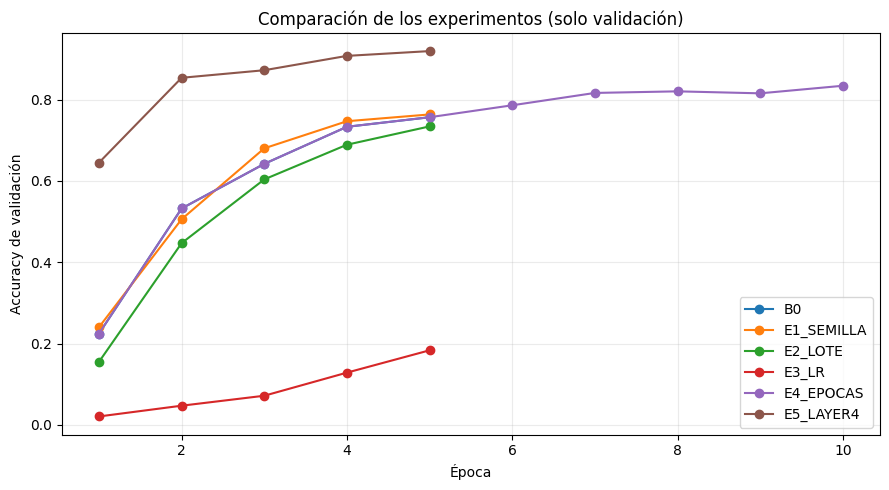

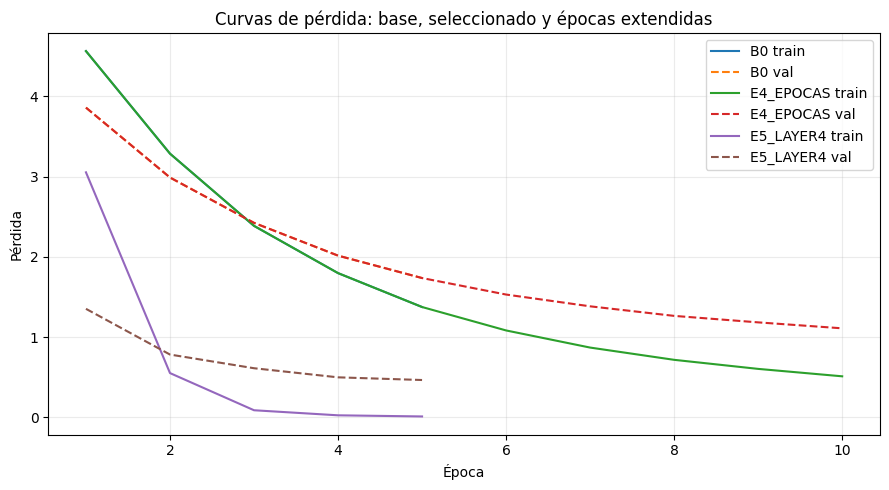

[6/10] Selección concluida; prueba continúa intacta en esta ejecución


In [6]:
print('[6/10] Comparación y selección usando SOLO validación')
assert len(RESULTS)==len(EXPERIMENTS),'Faltan ejecuciones; NO seleccionar modelo'
summary=pd.DataFrame([{k:v for k,v in r.items() if k not in ('history','checkpoint')} for r in RESULTS])
summary=summary[['id','seed','batch_size','lr','epochs','finetune_layer4',
                 'trainable','best_epoch','best_val_acc','best_val_loss','seconds']]
print(summary.to_string(index=False))
summary.to_csv(EVID_DIR/'comparativa_validacion.csv',index=False)
# criterio fijado: mayor accuracy; empate menor val_loss; empate menos entrenables;
# empate id lexicográfico para desempate determinista.
ordered=sorted(RESULTS,key=lambda r:(-r['best_val_acc'],r['best_val_loss'],r['trainable'],r['id']))
WINNER=ordered[0]
print('CONFIGURACIÓN SELECCIONADA:',WINNER['id'])
print('Criterio: mayor val_acc; empate menor val_loss, menos parámetros entrenables e ID')
print('Checkpoint seleccionado:',WINNER['checkpoint'])
fig,ax=plt.subplots(figsize=(9,5))
for r in RESULTS:
    ax.plot([h['epoch'] for h in r['history']],
            [h['val_acc'] for h in r['history']],marker='o',label=r['id'])
ax.set(xlabel='Época',ylabel='Accuracy de validación',title='Comparación de los experimentos (solo validación)')
ax.grid(alpha=0.25);ax.legend();fig.tight_layout()
fig.savefig(EVID_DIR/'curvas_validacion.png',dpi=160)
plt.show()
fig,ax=plt.subplots(figsize=(9,5))
for r in RESULTS:
    if r['id'] in ('B0',WINNER['id'],'E4_EPOCAS'):
        ax.plot([h['epoch'] for h in r['history']],[h['train_loss'] for h in r['history']],label=r['id']+' train')
        ax.plot([h['epoch'] for h in r['history']],[h['val_loss'] for h in r['history']],linestyle='--',label=r['id']+' val')
ax.set(xlabel='Época',ylabel='Pérdida',title='Curvas de pérdida: base, seleccionado y épocas extendidas')
ax.grid(alpha=0.25);ax.legend();fig.tight_layout()
fig.savefig(EVID_DIR/'curvas_perdida.png',dpi=160)
plt.show()
print('[6/10] Selección concluida; prueba continúa intacta en esta ejecución')

### Respuestas verificadas — curvas y selección
1. En B0, la pérdida de entrenamiento bajó de **4.5653** a **1.3747** y la de validación de **3.8607** a **1.7359**. En E4, la pérdida de validación continuó descendiendo hasta **1.1090** en la época 10. No hay evidencia de un aumento sostenido de pérdida de validación en E4, aunque un experimento corto no excluye sobreajuste futuro.
2. Accuracy es la proporción de clasificaciones correctas; no muestra en cuáles de las 102 clases se producen errores.
3. Comparativa final, accuracy de validación: B0 **75.69%**, E1 **76.37%**, E2 **73.43%**, E3 **18.33%**, E4 **83.43%**, E5 **91.96%**. Se seleccionó **E5_LAYER4** por máxima accuracy de validación (desempates: menor pérdida, menos parámetros entrenables, ID). E5 alcanzó **88.68% Top-1** y **94.94% Top-3** en prueba. Los resultados anteriores de prueba eran conocidos históricamente; esta ejecución no los utilizó para escoger ganador.


## 6. Verificación del ganador y evaluación final en prueba

In [7]:
print('[7/10] Reconstrucción independiente del ganador y AUDITORÍA FINAL')
assert WINNER['checkpoint'] and Path(WINNER['checkpoint']).exists()
ckpt=torch.load(WINNER['checkpoint'],map_location='cpu',weights_only=True)
assert ckpt['config']['id']==WINNER['id']
FINAL_MODEL=build_model(ckpt['config']['finetune_layer4'])
FINAL_MODEL.load_state_dict(ckpt['state_dict'],strict=True)
FINAL_MODEL.eval()
FINAL_AUDIT=audit_model(FINAL_MODEL,print_details=True)
assert FINAL_AUDIT['total']==11228838
assert FINAL_AUDIT['trainable']==ckpt['architecture']['trainable']
print('Comparación base vs final:',ARQUITECTURA_BASE['trainable'],'->',FINAL_AUDIT['trainable'],'entrenables')

print('[8/10] Comienza evaluación FINAL de prueba (después de seleccionar).')
test_loader=DataLoader(test_ds,batch_size=WINNER['batch_size'],shuffle=False,num_workers=NUM_WORKERS)
loss_fn=nn.CrossEntropyLoss()
TEST_LOSS_SUM=0.;n=0; TOP1=0;TOP3=0
real=[];pred=[];top3_ids=[];probs_saved=[]
with torch.no_grad():
    for x,y in test_loader:
        logits=FINAL_MODEL(x.to(DEVICE))
        loss=loss_fn(logits,y.to(DEVICE))
        probabilities=torch.softmax(logits,dim=1).cpu()
        p3=probabilities.topk(3,dim=1).indices
        guess=p3[:,0]
        TEST_LOSS_SUM+=loss.item()*len(y);n+=len(y)
        TOP1+=(guess==y).sum().item()
        TOP3+=(p3==y[:,None]).any(dim=1).sum().item()
        real.extend(y.tolist());pred.extend(guess.tolist())
        top3_ids.extend(p3.tolist());probs_saved.extend(probabilities.tolist())
assert n==len(test_ds)
TEST_METRICS={'loss':TEST_LOSS_SUM/n,'top1':TOP1/n,'top3':TOP3/n,'examples':n}
print('Prueba final:',TEST_METRICS)
print('ADVERTENCIA: se conocían resultados históricos de test de una ejecución anterior. No se usaron para selección en este notebook.')

[7/10] Reconstrucción independiente del ganador y AUDITORÍA FINAL
Parámetros: {'total': 11228838, 'trainable': 8446054, 'frozen': 2782784}
  conv1      (1, 3, 224, 224) -> (1, 64, 112, 112)
  bn1        (1, 64, 112, 112) -> (1, 64, 112, 112)
  relu       (1, 64, 112, 112) -> (1, 64, 112, 112)
  maxpool    (1, 64, 112, 112) -> (1, 64, 56, 56)
  layer1     (1, 64, 56, 56) -> (1, 64, 56, 56)
  layer2     (1, 64, 56, 56) -> (1, 128, 28, 28)
  layer3     (1, 128, 28, 28) -> (1, 256, 14, 14)
  layer4     (1, 256, 14, 14) -> (1, 512, 7, 7)
  avgpool    (1, 512, 7, 7) -> (1, 512, 1, 1)
  fc         (1, 512) -> (1, 102)
Comparación base vs final: 52326 -> 8446054 entrenables
[8/10] Comienza evaluación FINAL de prueba (después de seleccionar).
Prueba final: {'loss': 0.5507627359239585, 'top1': 0.8868108635550496, 'top3': 0.949422670352903, 'examples': 6149}
ADVERTENCIA: se conocían resultados históricos de test de una ejecución anterior. No se usaron para selección en este notebook.


## 7. Matriz de confusión, errores y predicciones

[9/10] Métricas por clase, matriz y análisis de errores
              precision    recall  f1-score   support

      Flor 1       0.49      1.00      0.66        20
      Flor 2       1.00      0.95      0.97        40
      Flor 3       0.41      0.45      0.43        20
      Flor 4       0.71      0.61      0.66        36
      Flor 5       1.00      0.84      0.92        45
      Flor 6       0.96      0.96      0.96        25
      Flor 7       0.87      1.00      0.93        20
      Flor 8       0.93      1.00      0.96        65
      Flor 9       0.69      0.85      0.76        26
     Flor 10       0.96      1.00      0.98        25
     Flor 11       0.87      0.79      0.83        67
     Flor 12       0.94      0.94      0.94        67
     Flor 13       0.94      1.00      0.97        29
     Flor 14       0.90      1.00      0.95        28
     Flor 15       0.94      1.00      0.97        29
     Flor 16       0.56      0.90      0.69        21
     Flor 17       0.98  

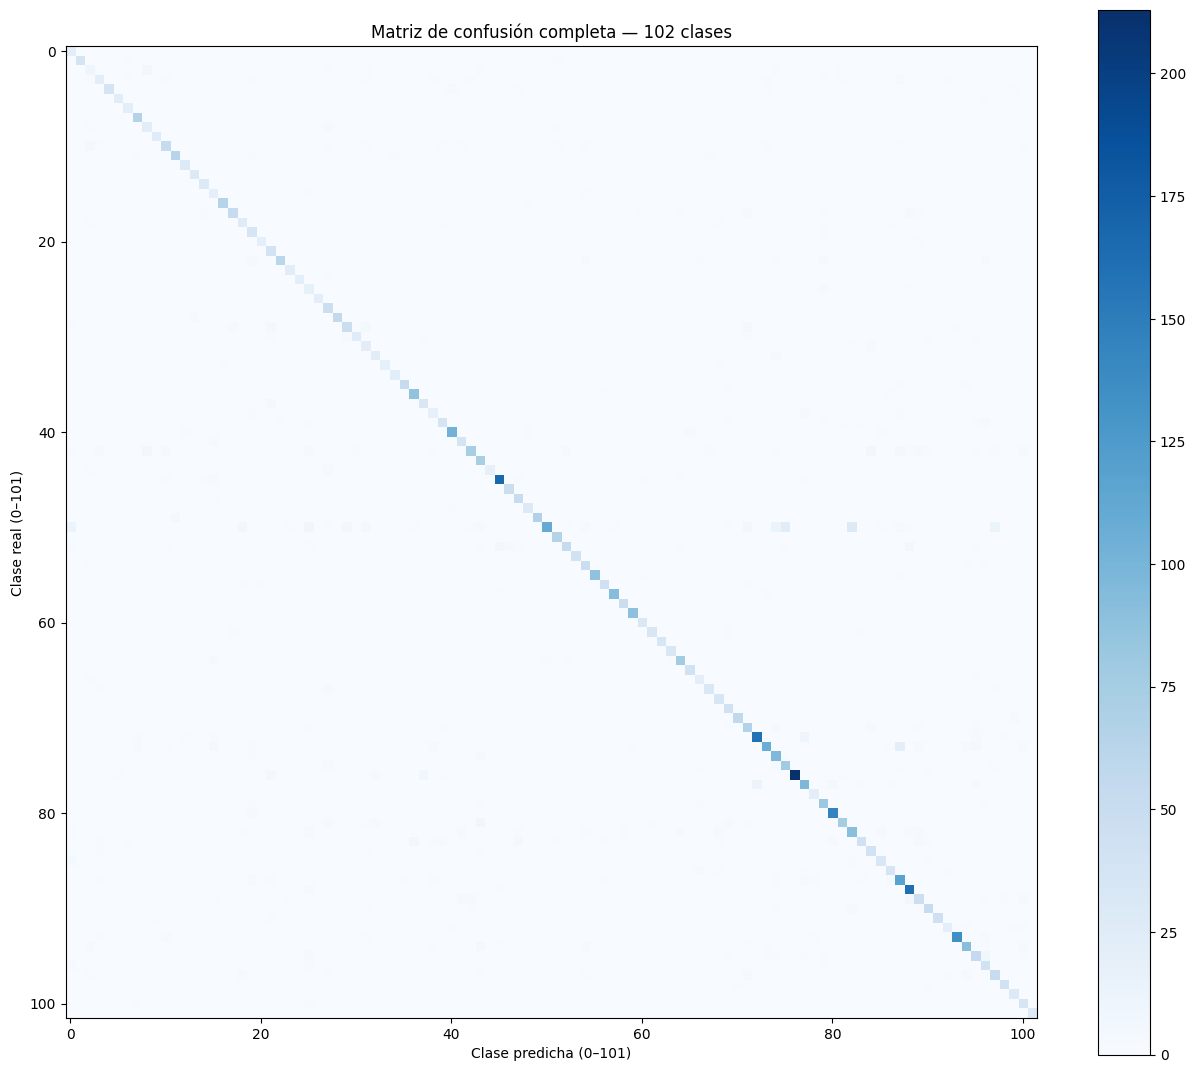

Dos confusiones más frecuentes (reales -> predichas):
  Flor 51 -> Flor 83: 27 casos
  Flor 51 -> Flor 76: 24 casos
Errores disponibles: 696


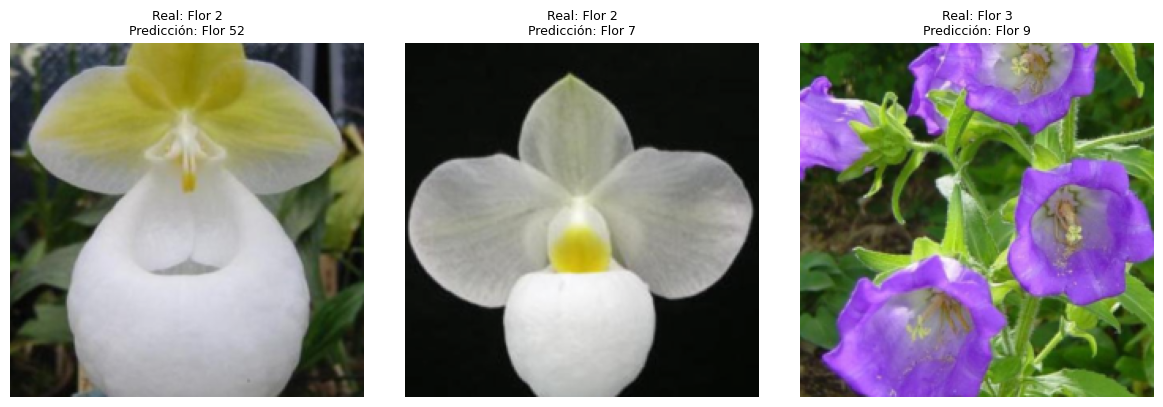

Cinco predicciones de prueba:
  ejemplo 0: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.863), Flor 19 (0.033), Flor 55 (0.008)
  ejemplo 1: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.755), Flor 86 (0.033), Flor 76 (0.031)
  ejemplo 2: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.517), Flor 34 (0.035), Flor 55 (0.028)
  ejemplo 3: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.980), Flor 76 (0.005), Flor 86 (0.003)
  ejemplo 4: real=Flor 1; pred=Flor 1; Top-3=Flor 1 (0.995), Flor 76 (0.002), Flor 91 (0.001)
Top-1 de toda prueba: 0.8868 | Top-3: 0.9494


In [8]:
print('[9/10] Métricas por clase, matriz y análisis de errores')
cm=confusion_matrix(real,pred,labels=list(range(NUM_CLASSES)))
report=classification_report(real,pred,labels=list(range(NUM_CLASSES)),target_names=CLASSES,zero_division=0,output_dict=True)
pd.DataFrame(report).transpose().to_csv(EVID_DIR/'metricas_por_clase.csv')
print(classification_report(real,pred,labels=list(range(NUM_CLASSES)),target_names=CLASSES,zero_division=0))
fig,ax=plt.subplots(figsize=(13,11))
im=ax.imshow(cm,cmap='Blues',interpolation='nearest')
fig.colorbar(im,ax=ax)
ax.set(xlabel='Clase predicha (0–101)',ylabel='Clase real (0–101)',title='Matriz de confusión completa — 102 clases')
fig.tight_layout();fig.savefig(EVID_DIR/'matriz_confusion.png',dpi=180);plt.show()
cm_errors=cm.copy();np.fill_diagonal(cm_errors,0)
error_pairs=sorted([(int(cm_errors[a,b]),a,b) for a in range(NUM_CLASSES)
                    for b in range(NUM_CLASSES) if a!=b and cm_errors[a,b]>0],reverse=True)
print('Dos confusiones más frecuentes (reales -> predichas):')
for count,a,b in error_pairs[:2]:print(f'  {CLASSES[a]} -> {CLASSES[b]}: {count} casos')
incorrect=[i for i,(r,p) in enumerate(zip(real,pred)) if r!=p]
print('Errores disponibles:',len(incorrect))
assert len(incorrect)>=3,'No existen tres errores para analizar; documentar esta limitación'
# La transformación incluye normalización; invertirla solo para mostrar imágenes.
mean=np.array([0.485,0.456,0.406])[:,None,None]
std=np.array([0.229,0.224,0.225])[:,None,None]
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,i in zip(axes,incorrect[:3]):
    x,y=test_ds[i]
    displayed=np.clip(x.numpy()*std+mean,0,1).transpose(1,2,0)
    ax.imshow(displayed);ax.axis('off')
    ax.set_title(f'Real: {CLASSES[y]}\nPredicción: {CLASSES[pred[i]]}',fontsize=9)
fig.tight_layout();fig.savefig(EVID_DIR/'tres_errores.png',dpi=160);plt.show()
print('Cinco predicciones de prueba:')
for i in range(min(5,len(test_ds))):
    ids=top3_ids[i]
    top3_str=', '.join(f'{CLASSES[j]} ({probs_saved[i][j]:.3f})' for j in ids)
    print(f'  ejemplo {i}: real={CLASSES[real[i]]}; pred={CLASSES[pred[i]]}; Top-3={top3_str}')
print('Top-1 de toda prueba:',f"{TEST_METRICS['top1']:.4f}",'| Top-3:',f"{TEST_METRICS['top3']:.4f}")

### Respuestas verificadas — errores, métricas y Top-3
1. Confusiones más frecuentes en prueba: **Flor 51 → Flor 83: 27 casos** y **Flor 51 → Flor 76: 24 casos**. Las tres imágenes de error están incrustadas en la salida de esta ejecución CPU; similitud de características visuales es una hipótesis, no una causa demostrada.
2. **Precisión:** aciertos entre los ejemplos predichos como una clase. **Recall:** aciertos entre los ejemplos reales de esa clase. **F1:** media armónica de ambas.
3. Las imágenes de error y sus etiquetas están incrustadas en esta ejecución CPU. Su interpretación visual se incluye debajo; no se verificó experimentalmente una causa de las predicciones.
4. En los cinco ejemplos registrados, la clase real Flor 1 aparece como **Top-1**, por lo que también está dentro del Top-3.
5. Sobre las **6149** imágenes de prueba: Top-1 **88.6811%** y Top-3 **94.9423%**. Top-3 acepta como correcta una predicción si la clase real está en cualquiera de los tres primeros lugares; no implica probabilidades calibradas.


**Análisis visual de los tres errores CPU:** En el primer error (Flor 2 → Flor 52), la flor presenta pétalos blancos, zona superior amarilla y un pétalo inferior grande. En el segundo (Flor 2 → Flor 7) hay pétalos blancos, centro amarillo y fondo oscuro. Comparten etiqueta real, pero el encuadre, el fondo y la distribución del amarillo difieren. En el tercero (Flor 3 → Flor 9), varias flores moradas con corolas en campana aparecen entre hojas verdes. Son diferencias observables en las imágenes; no establecen causalmente el motivo del error.


## 8. Guardado final, nueva carga e inferencia reproducible

In [11]:
print('[10/10] Exportación final y comprobación de carga independiente')
EXPORT_PATH=ROOT/'modelo_entrenado.pth'

# Aseguramos que todas las versiones en la metadata sean strings nativos primitivos de Python para evitar problemas de tipos complejos como TorchVersion
clean_versions = {k: str(v) for k, v in VERSIONS.items()}

FINAL_META={'architecture':'resnet18','weights_enum':'ResNet18_Weights.DEFAULT',
            'num_classes':NUM_CLASSES,'class_labels':CLASSES,
            'transform_repr':str(TRANSFORM),'input_shape':[3,224,224],
            'best_experiment':WINNER['id'],'best_epoch':WINNER['best_epoch'],
            'config':WINNER and {key:WINNER[key] for key in ('seed','batch_size','lr','epochs','finetune_layer4')},
            'versions':clean_versions,'device_used':str(DEVICE),
            'selection':'validation accuracy > val loss > fewer trainable params > id',
            'test_metrics':TEST_METRICS,'audit':{'total':FINAL_AUDIT['total'],
                                                'trainable':FINAL_AUDIT['trainable'],
                                                'frozen':FINAL_AUDIT['frozen']}}
# Los modelos/transformaciones no son objetos serializados: se reconstruyen en código.
torch.save({'state_dict':FINAL_MODEL.state_dict(),'metadata':FINAL_META},EXPORT_PATH)
with (ROOT/'metadata.json').open('w',encoding='utf8') as f:json.dump(FINAL_META,f,ensure_ascii=False,indent=2)
with (ROOT/'resultados_experimentos.json').open('w',encoding='utf8') as f:
    json.dump(RESULTS,f,ensure_ascii=False,indent=2)

# Cargamos con weights_only=False ya que es nuestro propio archivo de total confianza
RESTORED=torch.load(EXPORT_PATH,map_location='cpu',weights_only=False)
RESTORED_MODEL=build_model(RESTORED['metadata']['config']['finetune_layer4'])
RESTORED_MODEL.load_state_dict(RESTORED['state_dict'],strict=True)
RESTORED_MODEL.eval()
x0,y0=test_ds[0]
with torch.no_grad():
    original=FINAL_MODEL(x0.unsqueeze(0).to(DEVICE))
    restored=RESTORED_MODEL(x0.unsqueeze(0).to(DEVICE))
assert torch.allclose(original,restored,atol=1e-6,rtol=1e-5),'Discrepancia en predicción al cargar checkpoint'
print('Modelo restaurado correctamente; predicción coincide con el original')
print('Real:',CLASSES[y0],'| Pred:',CLASSES[int(restored.argmax(1).item())])
print('Guardado:',EXPORT_PATH)
print('Metadatos:',ROOT/'metadata.json')
print('Evidencias:',EVID_DIR)
print('Entrenamientos realizados:',len(RESULTS),'| modelo final:',WINNER['id'])
print('FIN: entrega técnica producida; comprobar archivos y descargar carpeta desde Colab.')

[10/10] Exportación final y comprobación de carga independiente
Modelo restaurado correctamente; predicción coincide con el original
Real: Flor 1 | Pred: Flor 1
Guardado: /content/flowers102_proyecto/modelo_entrenado.pth
Metadatos: /content/flowers102_proyecto/metadata.json
Evidencias: /content/flowers102_proyecto/evidencias
Entrenamientos realizados: 6 | modelo final: E5_LAYER4
FIN: entrega técnica producida; comprobar archivos y descargar carpeta desde Colab.


### Respuestas verificadas — guardado e inferencia
1. Los pesos por sí solos no identifican arquitectura ni orden de clases; deben acompañarse de transformaciones y metadatos. Se guardaron `modelo_entrenado.pth`, `metadata.json` y `resultados_experimentos.json`.
2. `softmax` transforma logits en valores entre 0 y 1 que suman 1; una probabilidad alta no garantiza que el modelo esté calibrado ni que la clasificación sea correcta.
3. En los **cinco ejemplos de prueba** impresos, la clase real fue Flor 1 y el Top-1 fue Flor 1. E5 descongeló `layer4` y mejoró validación de **75.69% a 91.96%** respecto a B0. El checkpoint fue cargado estrictamente y la predicción coincidió con la del modelo original. Esta comprobación no sustituye un nuevo reentrenamiento completo desde cero.
